In [1]:
import matplotlib.pyplot as plt
import numpy as np
import optax
from sklearn.metrics import mean_squared_error as mse, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from neural_network import NeuralNetwork, mse, mse_der, sigmoid, sigmoid_der, ReLU, ReLU_der
from runge_data import split_scale, design_matrix, runge_data

I dette prosjektet lurer jeg på om jupyter notebooks kan være smarte å bruke i og med at det vil ta lang tid å trene opp nettverk hver gang en ønsker å plotte osv.

In [2]:
# generating and scaling the runge data
x, y = runge_data()
p = 12
ts = 0.2
rs = 2026
X = design_matrix(x, p)
X_train_scaled, X_test_scaled, y_train_centered, y_test_centered = split_scale(X, y, ts, rs)
y_train_centered = y_train_centered.reshape(-1, 1)
y_test_centered = y_test_centered.reshape(-1, 1)

In [3]:
# initializing the neural networks
network_batch_size, network_input_size = X.shape

layer_output_sizes_1 = [50, 1]
layer_output_sizes_2 = [50, 100, 1]
activation_funcs_1 = [sigmoid, lambda _: _]
activation_ders_1 = [sigmoid_der, lambda _: 1]
activation_funcs_2 = [sigmoid, sigmoid, lambda _: _]
activation_ders_2 = [sigmoid_der, sigmoid_der, lambda _: 1]
cost_func = mse
cost_der = mse_der

network_1 = NeuralNetwork(
    network_input_size, layer_output_sizes_1, activation_funcs_1, activation_ders_1, cost_func, cost_der
    )
network_2 = NeuralNetwork(
    network_input_size, layer_output_sizes_2, activation_funcs_2, activation_ders_2, cost_func, cost_der
    )

# initialize network weights according to LeCun initialization with zero bias
vars_1 = np.zeros((2, 2))
vars_2 = np.zeros((3, 2))
vars_1[0, :] = (1/p, 0)
vars_1[1, :] = (1/50, 0)
vars_2[0, :] = (1/p, 0)
vars_2[1, :] = (1/50, 0)
vars_2[2, :] = (1/100, 0)

network_1.initialize_layers(vars_1, rs)
network_2.initialize_layers(vars_2, rs)

In [4]:
# training:
print(network_1.cost(X_test_scaled, y_test_centered))
optimizer = optax.adam(learning_rate = 0.01)
network_1.train_pgd(X_train_scaled, y_train_centered, optimizer, n_epochs = 1000)
print(network_1.cost(X_test_scaled, y_test_centered))

0.0964907230580528
0.011315309221190515


In [11]:
print(network_2.cost(X_test_scaled, y_test_centered))
optimizer = optax.adam(learning_rate = 0.01)
network_2.train_pgd(X_train_scaled, y_train_centered, optimizer, n_epochs = 1000)
print(network_2.cost(X_test_scaled, y_test_centered))

0.09170425211239662
0.016552553560171247


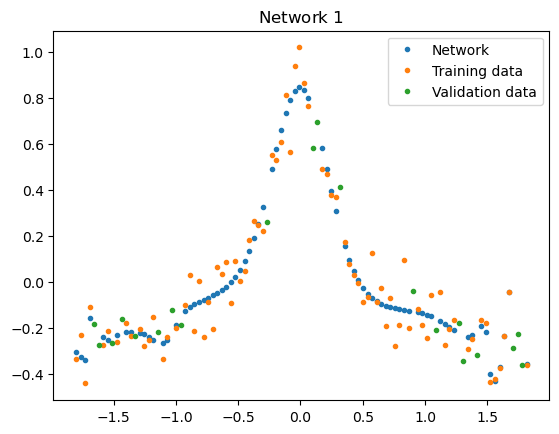

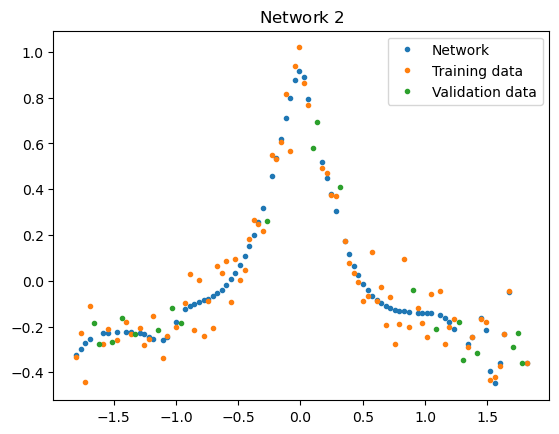

In [16]:
#plotting:
plt.plot(X_train_scaled[:, 0], network_1.predict(X_train_scaled), ".", label = "Network")
plt.plot(X_train_scaled[:, 0], y_train_centered, ".", label = "Training data")
plt.plot(X_test_scaled[:, 0], y_test_centered, ".", label = "Validation data")
plt.title("Network $1$")
plt.legend()
plt.show()

plt.plot(X_train_scaled[:, 0], network_2.predict(X_train_scaled), ".", label = "Network")
plt.plot(X_train_scaled[:, 0], y_train_centered, ".", label = "Training data")
plt.plot(X_test_scaled[:, 0], y_test_centered, ".", label = "Validation data")
plt.title("Network $2$")
plt.legend()
plt.show()